# Лабораторная работа № 2. Регрессионная модель CPU Mark

Целевая переменная: $y=\ln(\mathrm{CPU\ Mark})$. Используются восемь стандартизованных
регрессоров и свободный член. Обучение: 1365 CPU; отложенная выборка: 300 CPU.

В один ноутбук объединены расчёты из `extra_sample.ipynb`, `08_determination.ipynb`,
`09_model_adequacy.ipynb` и `10_coefficient_significance.ipynb`. Добавлены графическая
оценка однородности и анализ остатков. Состав модели и разбиение из ЛР1 сохранены.

Все результаты и рисунки сохранены в файле. Для повторного выполнения нужны
Python, NumPy, pandas, SciPy, Matplotlib и IPython. Снимок исходных CSV встроен
в следующую свёрнутую ячейку; отдельные файлы данных и доступ к сети не требуются.

Источник данных и исходных расчётов: [monkofwst/smmo, ветка timur, коммит 55ce43a](https://github.com/monkofwst/smmo/tree/55ce43a308433e5c8f2574d103a8f52207b21b90/lab2). Методическая основа: лекция 2, слайд 9; лекция 3, слайды 2–29.

In [1]:
import base64, io, zipfile

DATA_ARCHIVE = "..."
archive = zipfile.ZipFile(io.BytesIO(base64.b64decode(DATA_ARCHIVE)))
print("Встроенный снимок данных загружен.")

Встроенный снимок данных загружен.


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

def read_csv(name, **kwargs):
    return pd.read_csv(io.BytesIO(archive.read(name)), **kwargs)

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:.6f}')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'figure.dpi': 120, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'grid.linewidth': 0.7,
})
BLUE, TEAL, ORANGE, RED = '#2364a0', '#178077', '#c46a22', '#be3e42'
alpha = 0.05
dataset = read_csv('all_data_processed.csv', index_col='row_id').sort_index()
training = dataset.loc[dataset['split'].eq('train')].copy()
test = dataset.loc[dataset['split'].eq('test')].copy()

## 1–3. Модель, матрицы и предсказанные значения

Берём готовые признаки и фиксированное разбиение из ЛР1. В регрессию входят
стандартизованные $\ln(1+\mathrm{cores})$, частота, $\ln(1+\mathrm{TDP})$,
$\ln(1+\mathrm{L3})$, возраст и три индикатора категорий.
Обозначения $b_0,\ldots,b_8$ используются в таблицах матриц в том же порядке.

$$G=X^TX,\qquad C=G^{-1},\qquad \hat y=XB.$$

Оценки коэффициентов получаем методом наименьших квадратов. Проверяем совпадение
матриц и прогнозов с сохранёнными результатами исходного расчёта.

In [3]:
feature_names = [
    'log1p_cores', 'base_clock_ghz', 'log1p_tdp', 'log1p_l3',
    'age_centered', 'manufacturer_Intel', 'manufacturer_Other', 'category_Laptop',
]
labels = ['Свободный член', 'Число ядер', 'Базовая частота', 'TDP', 'Кэш L3',
          'Возраст', 'Intel относительно AMD', 'Other относительно AMD',
          'Laptop относительно Desktop']
terms = ['const', *feature_names]
short_terms = [f'b{j}' for j in range(len(terms))]
Z = training[feature_names].to_numpy()
X = np.column_stack([np.ones(len(training)), Z])
y = training['ln_cpu_mark'].to_numpy()
B = np.linalg.lstsq(X, y, rcond=None)[0]
y_hat = X @ B
X_test = np.column_stack([np.ones(len(test)), test[feature_names]])
y_test = test['ln_cpu_mark'].to_numpy()
y_hat_test = X_test @ B
n, p = X.shape
k = p - 1
G = X.T @ X
C_frame = read_csv('error_matrix.csv')
C_frame.index = C_frame.columns
C = C_frame.loc[terms, terms].to_numpy()
np.testing.assert_allclose(G, read_csv('inf_matrix.csv').to_numpy(), rtol=0, atol=1e-9)
np.testing.assert_allclose(C @ G, np.eye(p), rtol=0, atol=1e-10)
np.testing.assert_allclose(y_hat, read_csv('predictions.csv')['y_hat'], rtol=0, atol=1e-10)
print(f'Обучение: {n}; тест: {len(test)}; коэффициентов: {p}; ранг X: {np.linalg.matrix_rank(X)}')
display(pd.DataFrame({'Обозначение': short_terms, 'Регрессор': terms,
                      'Фактор': labels, 'Коэффициент': B}))
print('Информационная матрица G:')
display(pd.DataFrame(G, index=short_terms, columns=short_terms).round(4))
print('Матрица ошибок C:')
display(pd.DataFrame(C, index=short_terms, columns=short_terms).round(6))
print('Первые 10 прогнозов на обучении:')
display(pd.DataFrame({'y = ln(CPU Mark)': y, 'Прогноз': y_hat}, index=training.index).head(10))

Обучение: 1365; тест: 300; коэффициентов: 9; ранг X: 9


,Обозначение,Регрессор,Фактор,Коэффициент
0,b0,const,Свободный член,7.172794
1,b1,log1p_cores,Число ядер,0.483894
2,b2,base_clock_ghz,Базовая частота,0.346360
3,b3,log1p_tdp,TDP,0.108749
4,b4,log1p_l3,Кэш L3,0.203161
5,b5,age_centered,Возраст,-0.319625
6,b6,manufacturer_Intel,Intel относительно AMD,0.144079
7,b7,manufacturer_Other,Other относительно AMD,-0.048037
8,b8,category_Laptop,Laptop относительно Desktop,0.094318


Информационная матрица G:


,b0,b1,b2,b3,b4,b5,b6,b7,b8
b0,1365.000000,0.000000,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000
b1,0.000000,1365.000000,555.686500,511.766700,1086.115500,-641.912600,66.345900,-410.610000,-359.131900
b2,-0.000000,555.686500,1365.000000,988.757500,643.129700,-280.409700,32.429400,-209.518100,-757.969600
b3,0.000000,511.766700,988.757500,1365.000000,502.365300,187.329100,-265.493200,-62.546000,-809.404800
b4,0.000000,1086.115500,643.129700,502.365300,1365.000000,-622.678800,121.398200,-567.629900,-277.258300
b5,0.000000,-641.912600,-280.409700,187.329100,-622.678800,1365.000000,-411.353400,263.905700,-15.287300
b6,0.000000,66.345900,32.429400,-265.493200,121.398200,-411.353400,1365.000000,-456.290800,166.989700
b7,0.000000,-410.610000,-209.518100,-62.546000,-567.629900,263.905700,-456.290800,1365.000000,208.349600
b8,-0.000000,-359.131900,-757.969600,-809.404800,-277.258300,-15.287300,166.989700,208.349600,1365.000000


Матрица ошибок C:


,b0,b1,b2,b3,b4,b5,b6,b7,b8
b0,0.000733,-0.000000,0.000000,-0.000000,-0.000000,0.000000,-0.000000,-0.000000,0.000000
b1,-0.000000,0.002303,0.000394,-0.000525,-0.001553,0.000551,0.000042,-0.000040,0.000205
b2,0.000000,0.000394,0.002156,-0.001412,-0.000475,0.000559,-0.000201,-0.000050,0.000405
b3,-0.000000,-0.000525,-0.001412,0.002482,-0.000235,-0.000890,0.000163,-0.000209,0.000503
b4,-0.000000,-0.001553,-0.000475,-0.000235,0.002557,0.000300,0.000139,0.000561,-0.000392
b5,0.000000,0.000551,0.000559,-0.000890,0.000300,0.001408,0.000241,0.000151,-0.000048
b6,-0.000000,0.000042,-0.000201,0.000163,0.000139,0.000241,0.000959,0.000343,-0.000142
b7,-0.000000,-0.000040,-0.000050,-0.000209,0.000561,0.000151,0.000343,0.001060,-0.000250
b8,0.000000,0.000205,0.000405,0.000503,-0.000392,-0.000048,-0.000142,-0.000250,0.001286


Первые 10 прогнозов на обучении:


,y = ln(CPU Mark),Прогноз
row_id,,
0,5.273000,5.327019
1,8.624432,8.211437
2,6.469250,6.353624
4,6.284134,6.062610
6,6.406880,6.368811
10,7.032624,6.992047
11,6.768493,6.905717
12,6.752270,6.554436
14,8.193953,8.007300


## 4. Оценка дисперсии ошибки по дополнительной группе

Сохранён способ отбора из исходного ноутбука: шесть факторов совпадают точно,
а среди подходящих строк выбираются 20 CPU с минимальным нормированным разбросом
частоты и возраста. CPU Mark при отборе не используется.

$$S_0^2=\frac{1}{m-1}\sum_{i=1}^{m}(y_i-\bar y)^2,\qquad \nu_0=m-1.$$

In [4]:
df = dataset.filter(regex="^raw_").rename(columns=lambda name: name.removeprefix("raw_"))
data = df.loc[df["specs_missing_count"].eq(0)]

fixed = [
    "manufacturer_Intel", "manufacturer_Other", "category_Laptop",
    "cores", "tdp_w", "l3_cache_mb",
]
clock, age = "base_clock_ghz", "years_ago"
size = 20
clock_scale, age_scale = data[[clock, age]].std()

best_score = float("inf")
extra = None

for _, group in data.groupby(fixed):
    if len(group) < size:
        continue

    clocks = sorted(group[clock].unique())
    for i, low in enumerate(clocks):
        for high in clocks[i:]:
            window = group.loc[group[clock].between(low, high)].sort_values(age)
            for start in range(len(window) - size + 1):
                candidate = window.iloc[start:start + size]
                clock_span = (candidate[clock].max() - candidate[clock].min()) / clock_scale
                age_span = (candidate[age].max() - candidate[age].min()) / age_scale
                score = max(clock_span, age_span)

                if score < best_score:
                    best_score = score
                    extra = candidate

if extra is None:
    print(f"Группа из {size} строк с совпадающими факторами не найдена.")
else:
    extra = extra.sort_index()
    print(f"Выбрано {len(extra)} CPU")
    display(extra[fixed + [clock, age]].agg(["min", "max"]))

Выбрано 20 CPU


,manufacturer_Intel,manufacturer_Other,category_Laptop,cores,tdp_w,l3_cache_mb,base_clock_ghz,years_ago
min,1,0,1,2,35.000000,3.000000,2.100000,15
max,1,0,1,2,35.000000,3.000000,2.500000,16


In [5]:
pd.testing.assert_frame_equal(extra.reset_index(drop=True), read_csv('cpu_extra_sample.csv'))
y_extra = np.log(extra['cpu_mark'].to_numpy())
df_0 = len(y_extra) - 1
S0_sq = y_extra.var(ddof=1)
overlap = int(extra.index.isin(training.index).sum())
print(f'S₀² = {S0_sq:.6f}; ν₀ = {df_0}')
print(f'Из {len(extra)} CPU дополнительной группы {overlap} входят в обучение, {len(extra)-overlap} — в тест.')

S₀² = 0.080688; ν₀ = 19
Из 20 CPU дополнительной группы 14 входят в обучение, 6 — в тест.


**Ограничение оценки.** Это разные CPU с близкими характеристиками, а не повторные
измерения одного объекта. Частота и возраст не полностью совпадают. Кроме того,
14 из 20 строк входят в обучение. Поэтому $S_0^2$ является приближённой оценкой,
а независимость оценок дисперсии для F- и t-критериев не обеспечена.
Зависимые от неё интервалы и проверки интерпретируются с этой оговоркой.

## 5. Дисперсии и ковариации оценок коэффициентов

По лекции 3 используем $\widehat{\operatorname{Cov}}(B)=S_0^2C$.
Стандартная ошибка коэффициента равна $\sqrt{S_0^2C_{jj}}$.

In [6]:
cov_B = S0_sq * C
standard_errors = np.sqrt(np.diag(cov_B))
display(pd.DataFrame(cov_B, index=short_terms, columns=short_terms).round(6))
display(pd.DataFrame({'Фактор': labels, 'Коэффициент': B,
                      'Дисперсия оценки': np.diag(cov_B),
                      'Стандартная ошибка': standard_errors}, index=short_terms))

,b0,b1,b2,b3,b4,b5,b6,b7,b8
b0,0.000059,-0.000000,0.000000,-0.000000,-0.000000,0.000000,-0.000000,-0.000000,0.000000
b1,-0.000000,0.000186,0.000032,-0.000042,-0.000125,0.000044,0.000003,-0.000003,0.000017
b2,0.000000,0.000032,0.000174,-0.000114,-0.000038,0.000045,-0.000016,-0.000004,0.000033
b3,-0.000000,-0.000042,-0.000114,0.000200,-0.000019,-0.000072,0.000013,-0.000017,0.000041
b4,-0.000000,-0.000125,-0.000038,-0.000019,0.000206,0.000024,0.000011,0.000045,-0.000032
b5,0.000000,0.000044,0.000045,-0.000072,0.000024,0.000114,0.000019,0.000012,-0.000004
b6,-0.000000,0.000003,-0.000016,0.000013,0.000011,0.000019,0.000077,0.000028,-0.000011
b7,-0.000000,-0.000003,-0.000004,-0.000017,0.000045,0.000012,0.000028,0.000086,-0.000020
b8,0.000000,0.000017,0.000033,0.000041,-0.000032,-0.000004,-0.000011,-0.000020,0.000104


,Фактор,Коэффициент,Дисперсия оценки,Стандартная ошибка
b0,Свободный член,7.172794,0.000059,0.007688
b1,Число ядер,0.483894,0.000186,0.013633
b2,Базовая частота,0.346360,0.000174,0.013190
b3,TDP,0.108749,0.000200,0.014152
b4,Кэш L3,0.203161,0.000206,0.014363
b5,Возраст,-0.319625,0.000114,0.010660
b6,Intel относительно AMD,0.144079,0.000077,0.008798
b7,Other относительно AMD,-0.048037,0.000086,0.009249
b8,Laptop относительно Desktop,0.094318,0.000104,0.010186


## 6. Прогноз и доверительный интервал около нулевой точки

Находим ближайшую к нулю точку в пространстве восьми стандартизованных регрессоров.
Строим 95%-й доверительный интервал для среднего отклика в шкале логарифма:

$$\hat y_*\pm t_{0.975,\nu_0}\sqrt{S_0^2x_*Cx_*^T}.$$

Это интервал для среднего отклика, не предиктивный интервал отдельного CPU.

In [7]:
nearest = np.argmin((Z ** 2).sum(axis=1))
x_star = X[nearest]
y_hat_star = x_star @ B
var_y_hat_star = x_star @ cov_B @ x_star
margin = stats.t.ppf(0.975, df=df_0) * np.sqrt(var_y_hat_star)
print(f'row_id ближайшего CPU: {training.index[nearest]}')
print(f'Прогноз ln(CPU Mark) = {y_hat_star:.6f}')
print(f'Дисперсия прогноза среднего = {var_y_hat_star:.6f}')
print(f'95%-й ДИ: [{y_hat_star-margin:.6f}; {y_hat_star+margin:.6f}]')

row_id ближайшего CPU: 1431
Прогноз ln(CPU Mark) = 7.274314
Дисперсия прогноза среднего = 0.000201
95%-й ДИ: [7.244612; 7.304016]


## 7. Остаточная дисперсия

$$e_i=y_i-\hat y_i,\qquad S_{\mathrm{ост}}^2=\frac{\sum e_i^2}{n-p}.$$

Используются все 1365 обучающих наблюдений, включая строки с совпадающими факторами.

In [8]:
residuals = y - y_hat
rss = np.sum(residuals ** 2)
df_res = n - p
S_ost_sq = rss / df_res
S_ost = np.sqrt(S_ost_sq)
r = residuals / S_ost
print(f'RSS = {rss:.6f}; νост = {df_res}')
print(f'Sост² = {S_ost_sq:.6f}; Sост = {S_ost:.6f}')

RSS = 222.884528; νост = 1356
Sост² = 0.164369; Sост = 0.405425


## 8. Коэффициент детерминации

$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

Основной результат относится к обучению. Для теста среднее фактического отклика
вычисляется отдельно; тестовые строки не участвуют в оценивании коэффициентов.

In [9]:
def determination(actual, predicted):
    rss_part = np.sum((actual - predicted) ** 2)
    tss_part = np.sum((actual - actual.mean()) ** 2)
    return {'n': len(actual), 'RSS': rss_part, 'TSS': tss_part, 'R²': 1-rss_part/tss_part}

quality = pd.DataFrame({'Обучение': determination(y, y_hat),
                        'Тест': determination(y_test, y_hat_test)}).T.astype({'n': int})
r2_train, r2_test = quality['R²']
display(quality)
print(f'Объяснено {r2_train:.2%} разброса ln(CPU Mark) на обучении; R² на тесте = {r2_test:.6f}.')

,n,RSS,TSS,R²
Обучение,1365,222.884528,1926.593641,0.884312
Тест,300,56.448497,447.062914,0.873735


Объяснено 88.43% разброса ln(CPU Mark) на обучении; R² на тесте = 0.873735.


## 9. Проверки адекватности

**Общий F-тест (лекция 3, слайд 16).** $H_0$: все восемь коэффициентов при
регрессорах равны нулю. $F=\frac{R^2}{1-R^2}\frac{n-p}{p-1}$.

**По остаточной дисперсии (слайд 18).** Сравниваем $S_{\mathrm{ост}}^2$ с $S_0^2$:
$F=S_{\mathrm{ост}}^2/S_0^2$. Используем верхнюю критическую границу, как в алгоритме
лекции. Расчёт по дополнительной группе является приближённым по причинам из пункта 4.

In [10]:
f_r2 = (r2_train / (1-r2_train)) * (df_res / k)
critical_r2 = stats.f.isf(alpha, k, df_res)
p_r2 = stats.f.sf(f_r2, k, df_res)
f_res = S_ost_sq / S0_sq
critical_res = stats.f.isf(alpha, df_res, df_0)
p_res = stats.f.sf(f_res, df_res, df_0)
print(f'Общий F-тест: F = {f_r2:.4f}; Fкрит = {critical_r2:.4f}; df = ({k}, {df_res})')
print('p-value < 1e-300' if p_r2 == 0 else f'p-value = {p_r2:.3g}')
print('Факторы совместно значимы.' if f_r2 > critical_r2 else 'Общая значимость не установлена.')
print(f'По остаточной дисперсии: F = {f_res:.4f}; Fкрит = {critical_res:.4f}; df = ({df_res}, {df_0})')
print(f'Приближённое p-value = {p_res:.4f}')
print('По алгоритму лекции модель не проходит проверку адекватности по остаточной дисперсии.'
      if f_res > critical_res else 'Оснований отвергнуть адекватность по этому сравнению недостаточно.')

Общий F-тест: F = 1295.6426; Fкрит = 1.9452; df = (8, 1356)
p-value < 1e-300
Факторы совместно значимы.
По остаточной дисперсии: F = 2.0371; Fкрит = 1.8828; df = (1356, 19)
Приближённое p-value = 0.0329
По алгоритму лекции модель не проходит проверку адекватности по остаточной дисперсии.


Общая значимость регрессии и качество её структуры — разные вопросы. Высокий $R^2$ и значимость факторов могут сочетаться с систематическими ошибками модели.

## 10. Значимость коэффициентов

Индивидуальные двусторонние t-тесты при $\alpha=0.05$:
$t_j=b_j/\sqrt{S_0^2C_{jj}}$, число степеней свободы $\nu_0=19$.
Выводы условны: учитываются ограничения $S_0^2$, результаты пункта 9 и диагностика
однородности. Базовые категории — AMD и Desktop.

In [11]:
t_values = B / standard_errors
t_critical = stats.t.isf(alpha/2, df_0)
p_values = 2 * stats.t.sf(np.abs(t_values), df_0)
significance = pd.DataFrame({'Фактор': labels, 'b': B, 'SE': standard_errors,
                              't': t_values, 'p-value': p_values,
                              'Значим при α=0,05': p_values < alpha}, index=terms)
print(f'Критическое |t| = {t_critical:.4f}; ν₀ = {df_0}')
significance_view = significance.copy()
significance_view['p-value'] = significance_view['p-value'].map('{:.3g}'.format)
display(significance_view.round(6))
for label, value, p_value in zip(labels[1:], B[1:], p_values[1:]):
    direction = 'положительная' if value > 0 else 'отрицательная'
    print(f'{label}: {direction} связь при фиксированных остальных факторах; '
          + ('значим по принятому тесту.' if p_value < alpha else 'значимость не установлена.'))

Критическое |t| = 2.0930; ν₀ = 19


,Фактор,b,SE,t,p-value,"Значим при α=0,05"
const,Свободный член,7.172794,0.007688,932.932358,9.5e-46,True
log1p_cores,Число ядер,0.483894,0.013633,35.494421,7.82e-19,True
base_clock_ghz,Базовая частота,0.346360,0.013190,26.258606,2.15e-16,True
log1p_tdp,TDP,0.108749,0.014152,7.684478,3.03e-07,True
log1p_l3,Кэш L3,0.203161,0.014363,14.144908,1.54e-11,True
age_centered,Возраст,-0.319625,0.010660,-29.984640,1.83e-17,True
manufacturer_Intel,Intel относительно AMD,0.144079,0.008798,16.375717,1.16e-12,True
manufacturer_Other,Other относительно AMD,-0.048037,0.009249,-5.193613,5.17e-05,True
category_Laptop,Laptop относительно Desktop,0.094318,0.010186,9.259904,1.79e-08,True


Число ядер: положительная связь при фиксированных остальных факторах; значим по принятому тесту.
Базовая частота: положительная связь при фиксированных остальных факторах; значим по принятому тесту.
TDP: положительная связь при фиксированных остальных факторах; значим по принятому тесту.
Кэш L3: положительная связь при фиксированных остальных факторах; значим по принятому тесту.
Возраст: отрицательная связь при фиксированных остальных факторах; значим по принятому тесту.
Intel относительно AMD: положительная связь при фиксированных остальных факторах; значим по принятому тесту.
Other относительно AMD: отрицательная связь при фиксированных остальных факторах; значим по принятому тесту.
Laptop относительно Desktop: положительная связь при фиксированных остальных факторах; значим по принятому тесту.


## 11. Графическая оценка однородности

Постоянство дисперсии означает, что разброс ошибок не зависит от характеристик CPU.
Большая остаточная дисперсия сама по себе не доказывает гетероскедастичность.

По лекции 3 (слайды 20, 22–25, 29) оцениваем ширину облака остатков против прогнозов
и факторов, а также сравниваем распределения по категориям. Рисунки приведены в
пунктах 12.4–12.6; итог по однородности — после них.

Это **графическая диагностика**, без формального p-value для гипотезы об однородности.
F-сравнение из пункта 9 проверяет адекватность модели и не заменяет эту диагностику.

## 12. Анализ остатков

Используем индивидуальные остатки обучающей выборки в шкале $\ln(\mathrm{CPU\ Mark})$:

$$e_i=y_i-\hat y_i,\qquad r_i=\frac{e_i}{S_{\mathrm{ост}}}.$$

Нормирование соответствует слайду 20 лекции 3. Это деление на общую оценку
стандартного отклонения; поправка на индивидуальный рычаг наблюдения здесь не применяется.
Положительный остаток означает занижение прогноза, отрицательный — завышение.

In [12]:
flag = np.abs(r) > 3
diag = pd.DataFrame({'Факт ln(CPU Mark)': y, 'Прогноз ln(CPU Mark)': y_hat,
                     'Остаток e': residuals, 'Нормированный остаток r': r}, index=training.index)
diag['Производитель'] = np.select(
    [training['raw_manufacturer_Intel'].eq(1), training['raw_manufacturer_Other'].eq(1)],
    ['Intel', 'Other'], default='AMD')
diag['Категория'] = np.where(training['raw_category_Laptop'].eq(1), 'Laptop', 'Desktop')
print(f'Средний остаток: {residuals.mean():.3e}')
print(f'Минимальный / максимальный остаток: {residuals.min():.6f} / {residuals.max():.6f}')
print(f'Число наблюдений с |r| > 3: {flag.sum()} из {n} ({flag.mean():.2%})')

Средний остаток: -1.564e-15
Минимальный / максимальный остаток: -1.969451 / 1.458244
Число наблюдений с |r| > 3: 7 из 1365 (0.51%)


Среднее остатков на обучении практически равно нулю в силу свойства МНК с константой. Само по себе это не подтверждает правильность формы модели, нормальность или независимость ошибок.

### 12.1. Распределение остатков

Гистограмма нормированных остатков и эталонная плотность $N(0,1)$.
При выполнении предпосылки нормальности ожидается примерно колоколообразная форма.
Оцениваем симметрию, центральную часть и хвосты (лекция 3, слайды 20–21).

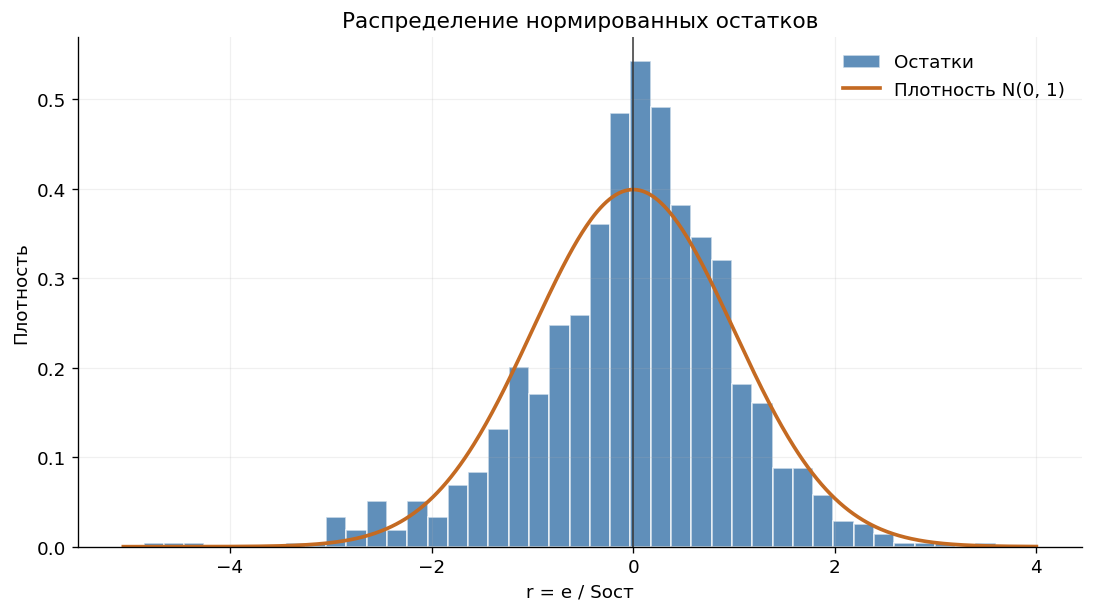

In [13]:
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.hist(r, bins='fd', density=True, color=BLUE, alpha=0.72, edgecolor='white', label='Остатки')
grid = np.linspace(min(-4, r.min()-0.2), max(4, r.max()+0.2), 600)
ax.plot(grid, stats.norm.pdf(grid), color=ORANGE, lw=2.2, label='Плотность N(0, 1)')
ax.axvline(0, color='#333333', lw=0.9)
ax.set(title='Распределение нормированных остатков', xlabel='r = e / Sост', ylabel='Плотность')
ax.legend(frameon=False)
plt.show()

Распределение имеет центральный пик около нуля, однако форма и хвосты отличаются от эталонной нормальной кривой. В частности, заметен удлинённый левый хвост; уточняем это по Q–Q графику.

### 12.2. Предсказанное значение против фактического

По горизонтали — фактический логарифм CPU Mark, по вертикали — предсказанный.
Диагональ $\hat y=y$ соответствует точному совпадению. Обучение и тест показаны
раздельно. Это дополнительная иллюстрация качества модели.

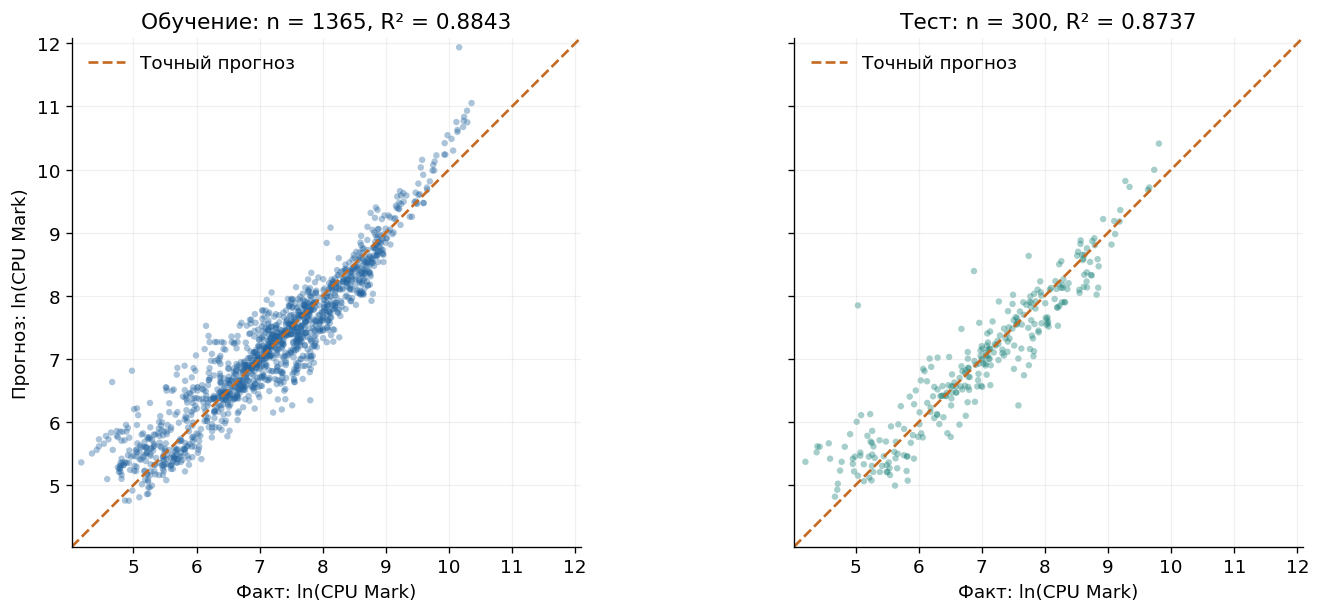

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, layout='constrained')
limits = [min(y.min(), y_test.min(), y_hat.min(), y_hat_test.min())-0.15,
          max(y.max(), y_test.max(), y_hat.max(), y_hat_test.max())+0.15]
for ax, actual, predicted, title, value, color in [
    (axes[0], y, y_hat, 'Обучение', r2_train, BLUE),
    (axes[1], y_test, y_hat_test, 'Тест', r2_test, TEAL),
]:
    ax.scatter(actual, predicted, s=15, alpha=0.38, color=color, edgecolors='none')
    ax.plot(limits, limits, '--', color=ORANGE, lw=1.6, label='Точный прогноз')
    ax.set(xlim=limits, ylim=limits, xlabel='Факт: ln(CPU Mark)',
           title=f'{title}: n = {len(actual)}, R² = {value:.4f}')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(frameon=False, loc='upper left')
axes[0].set_ylabel('Прогноз: ln(CPU Mark)')
plt.show()

Основная масса точек располагается вдоль диагонали; качество на тесте близко к обучению. При этом присутствуют заметные отклонения от диагонали. Высокий R² не означает выполнения всех предпосылок регрессии.

### 12.3. Q–Q график остатков

Сравниваем упорядоченные нормированные остатки с теоретическими квантилями $N(0,1)$.
При близости распределений точки идут вдоль диагонали. Q–Q график дополняет
гистограмму; отдельно этот способ не разбирается в предоставленных слайдах.

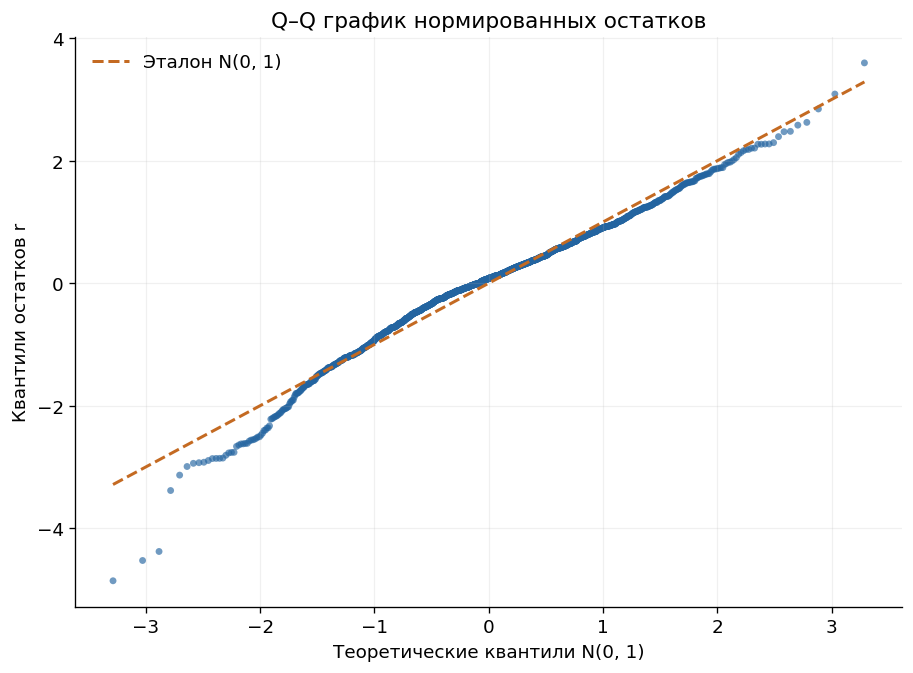

In [15]:
(theoretical, ordered), _ = stats.probplot(r, dist='norm')
fig, ax = plt.subplots(figsize=(7.5, 5.5), layout='constrained')
ax.scatter(theoretical, ordered, s=17, color=BLUE, alpha=0.65, edgecolors='none')
ax.plot([theoretical.min(), theoretical.max()], [theoretical.min(), theoretical.max()],
        '--', color=ORANGE, lw=1.8, label='Эталон N(0, 1)')
ax.set(title='Q–Q график нормированных остатков', xlabel='Теоретические квантили N(0, 1)',
       ylabel='Квантили остатков r')
ax.legend(frameon=False)
plt.show()

В центральной части точки ближе к прямой, а в хвостах отклоняются, особенно слева. Графическая диагностика указывает на отклонение от нормальности. Формальный тест нормальности в этом разделе не проводится.

### 12.4. Остатки против предсказанных значений

При отсутствии видимых нарушений ожидаем облако вокруг нуля с примерно постоянной
вертикальной шириной. Изменение ширины — признак гетероскедастичности, а смещение
среднего или изгиб — признак неверной структуры модели (лекция 3, слайды 23–26).

Красным отмечены наблюдения с $|r_i|>3$. Оранжевая линия показывает средние остатки
по десяти интервалам прогнозов; это описательное сглаживание.

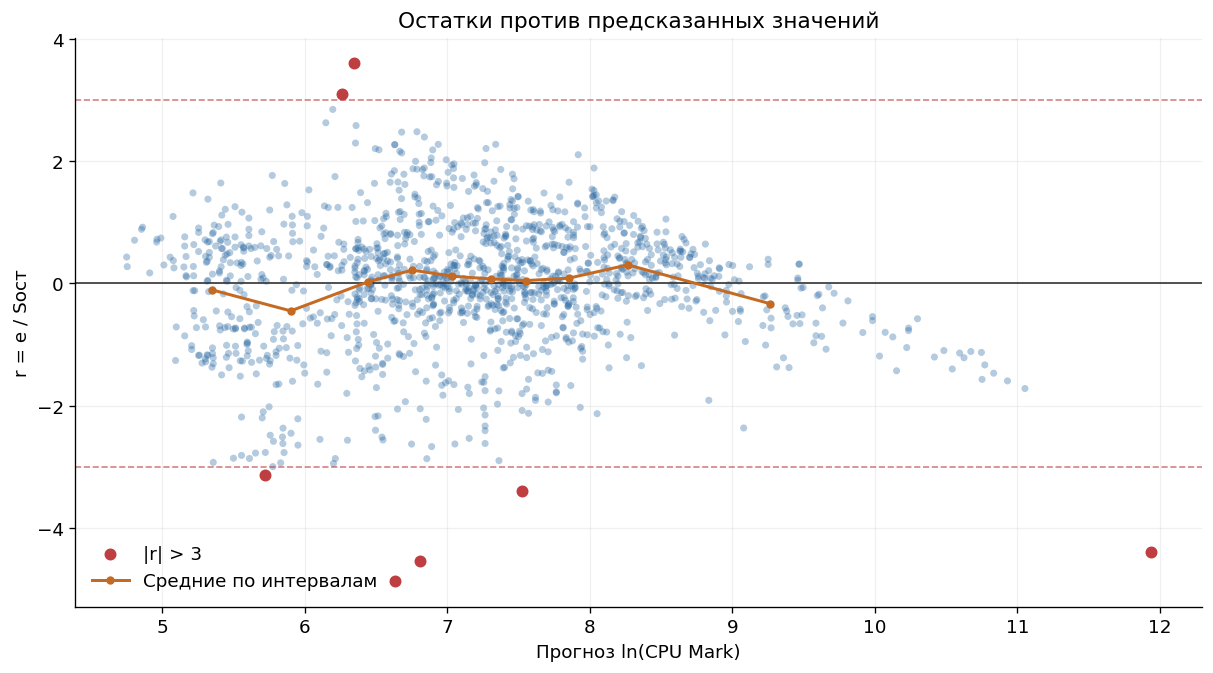

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
ax.scatter(y_hat[~flag], r[~flag], s=18, alpha=0.34, color=BLUE, edgecolors='none')
ax.scatter(y_hat[flag], r[flag], s=38, color=RED, label='|r| > 3', zorder=3)
ax.axhline(0, color='#333333', lw=1)
for bound in [-3, 3]:
    ax.axhline(bound, color=RED, ls='--', lw=1, alpha=0.65)
bins = pd.qcut(y_hat, 10, duplicates='drop')
profile = pd.DataFrame({'Прогноз': y_hat, 'r': r, 'Группа': bins}).groupby('Группа', observed=True)
means = profile[['Прогноз', 'r']].mean()
ax.plot(means['Прогноз'], means['r'], 'o-', color=ORANGE, lw=1.8, ms=4, label='Средние по интервалам')
ax.set(title='Остатки против предсказанных значений', xlabel='Прогноз ln(CPU Mark)', ylabel='r = e / Sост')
ax.legend(frameon=False)
plt.show()

Ширина облака неодинакова на разных участках. Средние по интервалам также отклоняются от нуля. Видны признаки неоднородности разброса и систематических отклонений; эти две особенности следует рассматривать отдельно.

### 12.5. Остатки против числовых регрессоров

Используем пять числовых регрессоров в том виде, в котором они входят в модель:
после соответствующих преобразований и стандартизации. Проверяем изменение разброса
и систематические отклонения (лекция 3, слайды 20–21, 26, 29).
Оранжевым показаны средние по квантильным интервалам; совпадающие границы объединяются.

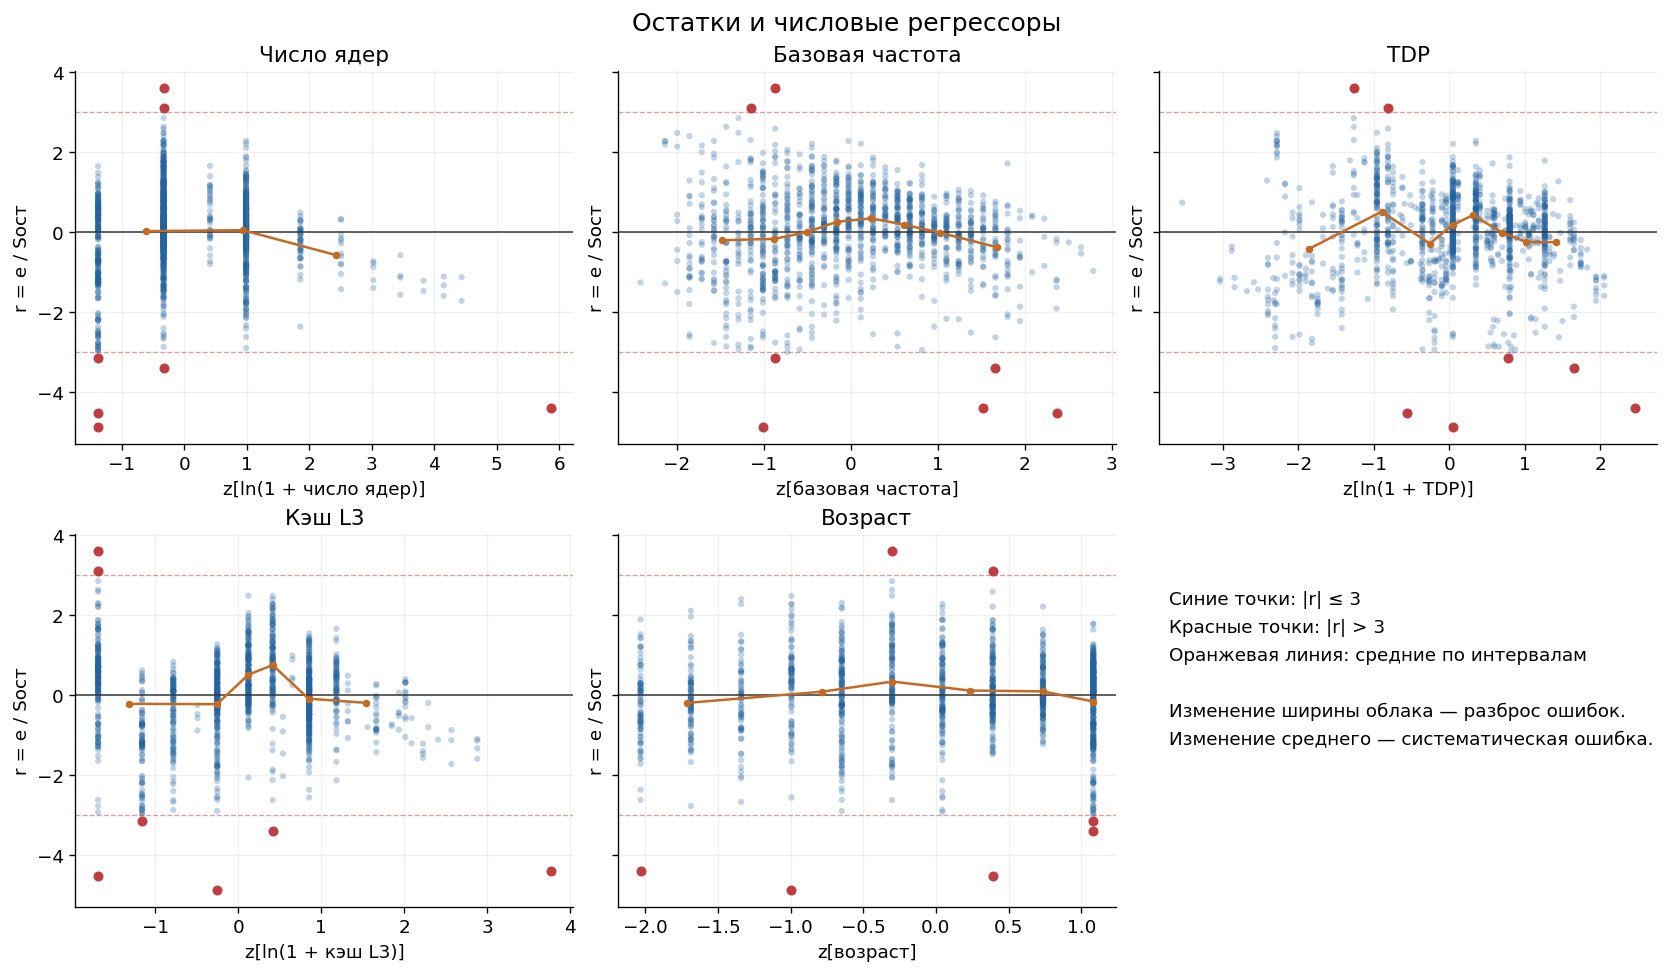

In [17]:
axis_labels = ['z[ln(1 + число ядер)]', 'z[базовая частота]', 'z[ln(1 + TDP)]',
               'z[ln(1 + кэш L3)]', 'z[возраст]']
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True, layout='constrained')
for j, ax in enumerate(axes.flat[:5]):
    values = Z[:, j]
    ax.scatter(values[~flag], r[~flag], s=14, alpha=0.28, color=BLUE, edgecolors='none')
    ax.scatter(values[flag], r[flag], s=25, color=RED, zorder=3)
    ax.axhline(0, color='#333333', lw=0.9)
    for bound in [-3, 3]:
        ax.axhline(bound, color=RED, ls='--', lw=0.8, alpha=0.5)
    intervals = pd.qcut(values, 8, duplicates='drop')
    grouped = pd.DataFrame({'x': values, 'r': r, 'interval': intervals}).groupby('interval', observed=True)
    points = grouped[['x', 'r']].mean()
    ax.plot(points['x'], points['r'], 'o-', color=ORANGE, lw=1.5, ms=3.5)
    ax.set(title=labels[j+1], xlabel=axis_labels[j], ylabel='r = e / Sост')
axes[1, 2].axis('off')
axes[1, 2].text(0.02, 0.85, 'Синие точки: |r| ≤ 3\nКрасные точки: |r| > 3\nОранжевая линия: средние по интервалам\n\nИзменение ширины облака — разброс ошибок.\nИзменение среднего — систематическая ошибка.',
                transform=axes[1, 2].transAxes, va='top', fontsize=11, linespacing=1.7)
fig.suptitle('Остатки и числовые регрессоры', fontsize=15)
plt.show()

На отдельных диапазонах факторов присутствуют смещение и изменение разброса. У части многоядерных CPU остатки заметно отрицательные: модель завышает их логарифм CPU Mark. Наличие таких структур указывает на возможную необходимость уточнения формы зависимости.

### 12.6. Остатки по производителю и категории

Для категориальных факторов сравниваем распределения через boxplot. Линия внутри
ящика — медиана; границы — квартили. Усы охватывают значения в пределах 1,5 IQR
от границ ящика. Точки за усами не тождественны наблюдениям за пределами трёх сигм.

Различия между этими группами являются описательной диагностикой. Они не заменяют
сравнение дисперсий при полном совпадении остальных факторов.

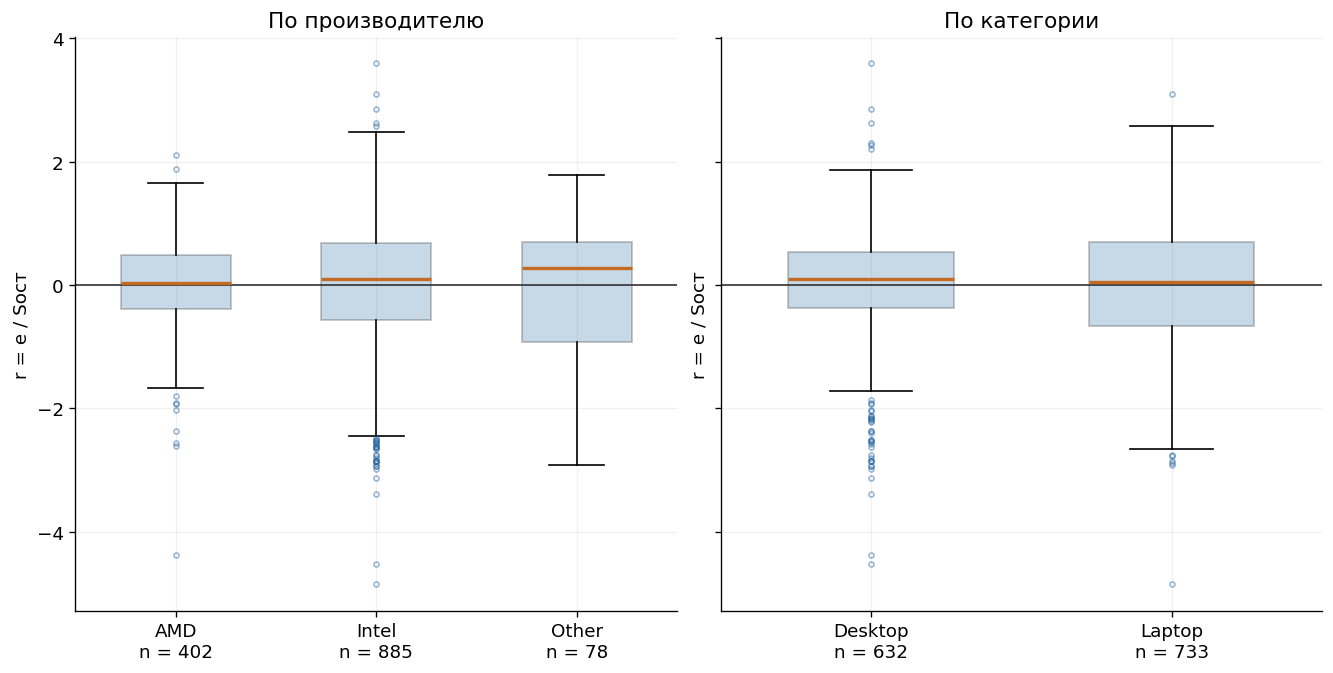

n  Среднее e  Стандартное отклонение e  Медиана e
Разбиение     Группа                                                      
Производитель AMD      402  -0.000000                  0.304900   0.013400
              Intel    885  -0.000000                  0.441700   0.036600
              Other     78  -0.000000                  0.413200   0.110600
Категория     Desktop  632  -0.000000                  0.381700   0.039400
              Laptop   733  -0.000000                  0.422900   0.021500

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True, layout='constrained')
for ax, column, order, title in [
    (axes[0], 'Производитель', ['AMD', 'Intel', 'Other'], 'По производителю'),
    (axes[1], 'Категория', ['Desktop', 'Laptop'], 'По категории'),
]:
    values = [diag.loc[diag[column].eq(item), 'Нормированный остаток r'].to_numpy() for item in order]
    boxes = ax.boxplot(values, tick_labels=[f'{item}\nn = {len(v)}' for item, v in zip(order, values)],
                       patch_artist=True, widths=0.55,
                       medianprops={'color': ORANGE, 'linewidth': 2},
                       flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.45, 'markeredgecolor': BLUE})
    for box in boxes['boxes']:
        box.set(facecolor=BLUE, alpha=0.25)
    ax.axhline(0, color='#333333', lw=1)
    ax.set(title=title, ylabel='r = e / Sост')
plt.show()

group_tables = []
for column in ['Производитель', 'Категория']:
    table = diag.groupby(column)['Остаток e'].agg(['count', 'mean', 'std', 'median'])
    table.columns = ['n', 'Среднее e', 'Стандартное отклонение e', 'Медиана e']
    group_tables.append(pd.concat({column: table}, names=['Разбиение', 'Группа']))
display(pd.concat(group_tables).round(4))

Размах, межквартильный размах и хвосты распределений различаются между группами. Это дополняет признаки неодинакового разброса на графиках против прогнозов и числовых факторов. Размеры групп также различаются, поэтому сравнение остаётся описательным.

### 12.7. Правило трёх сигм

По слайду 20 лекции 3 рассматриваем строки, для которых
$|r_i|>3$, то есть $|e_i|>3S_{\mathrm{ост}}$.
Это эвристический порог для дополнительного разбора, особенно при обнаруженных
отклонениях от нормальности. Строки из модели не удаляются.

`row_id` — исходный индекс строки с нуля, сохранённый в наборе данных.

In [19]:
outliers = diag.loc[flag, ['Факт ln(CPU Mark)', 'Прогноз ln(CPU Mark)', 'Остаток e', 'Нормированный остаток r']].copy()
outliers.insert(0, 'CPU Mark', training.loc[outliers.index, 'raw_cpu_mark'].astype(int))
outliers.insert(1, 'Ядра', training.loc[outliers.index, 'raw_cores'].astype(int))
outliers = outliers.loc[outliers['Нормированный остаток r'].abs().sort_values(ascending=False).index]
print(f'3Sост = {3*S_ost:.6f}; за порогом {len(outliers)} из {n} наблюдений ({len(outliers)/n:.2%}).')
display(outliers.round(4))
print('Отрицательный остаток: прогноз завышен. Положительный: прогноз занижен.')

3Sост = 1.216274; за порогом 7 из 1365 наблюдений (0.51%).


,CPU Mark,Ядра,Факт ln(CPU Mark),Прогноз ln(CPU Mark),Остаток e,Нормированный остаток r
row_id,,,,,,
708,106,1,4.663400,6.632900,-1.969500,-4.857700
1533,145,1,4.976700,6.812000,-1.835200,-4.526700
1420,25874,32,10.161000,11.936600,-1.775600,-4.379500
951,2446,2,7.802200,6.344000,1.458200,3.596800
1020,469,2,6.150600,7.522700,-1.372100,-3.384300
699,86,1,4.454300,5.724500,-1.270100,-3.132900
560,1837,2,7.515900,6.263700,1.252200,3.088500


Отрицательный остаток: прогноз завышен. Положительный: прогноз занижен.


### Порядок наблюдений и независимость

На слайдах 27–29 лекции 3 приведены графики автокорреляции и последовательности
остатков. В данном наборе строки соответствуют разным CPU и не образуют временной
последовательности измерений. Поэтому график по произвольному номеру строки и
сравнение соседних остатков не использованы для вывода о временной зависимости.
Независимость ошибок по выполненным графикам не установлена.

## Выводы по пунктам 11–12

1. **Однородность.** Графики против прогнозов и факторов, а также boxplot дают признаки
   непостоянства разброса ошибок. Однородность нельзя считать подтверждённой.
   Это качественный вывод; формальный тест однородности в пункте 11 не проводился.
2. **Нормальность.** Гистограмма и Q–Q график показывают отклонения от нормальной формы,
   особенно в левом хвосте. Нормальность графически не подтверждается.
3. **Структура модели.** На отдельных диапазонах факторов видны систематические
   отклонения. В частности, часть многоядерных CPU имеет завышенные прогнозы.
4. **Сильно отклоняющиеся наблюдения.** Найдены 7 строк с $|r_i|>3$.
   Они перечислены в таблице и сохранены в модели.
5. **Независимость.** Из-за отсутствия временного порядка проверка сериальной
   зависимости не выполнялась. Сделать вывод о независимости по этим рисункам нельзя.

Модель объясняет существенную часть разброса логарифма CPU Mark, однако высокий
коэффициент детерминации не исключает нарушений предпосылок. Выводы обычных F- и
t-тестов, доверительные интервалы и оценки значимости факторов следует трактовать
с учётом обнаруженных особенностей и ограничения дополнительной группы для $S_0^2$.